# 04 — Tiền xử lý ảnh  ·  Bước 5

**Bước 3 để lại gì cho bước này.** Chỉ cần 6 con số màu của vùng giữa ảnh, một hồi quy logistic đã
đoán đúng nguồn của **80%** ảnh nốt ruồi lành (đoán bừa được 25%). Trong khi đó, nếu chỉ biết loại
bệnh thì đoán được 41,5%. Như vậy bốn nguồn khác nhau rõ ở *cách ảnh trông ra*, không chỉ ở *loại bệnh
chúng có*. Với federated, đây chính là kiểu khác biệt giữa các bệnh viện mà các kịch bản Dirichlet
chưa hề mô phỏng.

Bước này thử ba cách chuẩn bị ảnh:

| Kiểu | Làm gì | Vì sao |
|---|---|---|
| **P0** | ép thẳng 600×450 về 224×224 | pipeline thô đang dùng, tổn thương bị kéo dẹt |
| **P1** | thu cạnh ngắn về 224 rồi cắt giữa 224×224 | giữ đúng tỉ lệ hình học, mất khoảng 12% mỗi bên trái/phải |
| **P2** | P1 + chuẩn hoá màu **Shades of Gray** | trung hoà màu ánh sáng của từng máy chụp |

Hai việc **không** làm, kèm lý do:

- **Xử lý viền đen.** Bước 3 đo được tỉ lệ viền đen ≤ 10%, chỉ đáng kể ở vidir_modern. Không đáng làm
  trước.
- **Xoá lông.** Chưa đo được tỉ lệ ảnh có lông, nên chưa có căn cứ. Ghi vào phần hạn chế.

Shades of Gray xử lý *từng ảnh một mình*, không cần biết ảnh của bệnh viện khác. Vì vậy dùng trong
federated không tốn gì về riêng tư. Nếu thay bằng chuẩn hoá theo thống kê của cả tập dữ liệu thì các
bệnh viện sẽ phải gửi thống kê đó cho nhau.

**Đo ở hai tầng:**

1. **Tầng rẻ, chỉ cần CPU, vài phút:** sau P2, còn đoán được nguồn không? Nếu chuẩn hoá màu xoá được
   "chữ ký" của từng nguồn thì phép thử đoán nguồn phải tụt về gần mức bừa.
2. **Tầng đắt, cần GPU:** độ chính xác của mô hình tập trung với P0/P1/P2, 3 seed mỗi kiểu. Tác dụng lên
   federated sẽ đo ở bước 8, khi đã có cách chia theo nguồn thật (bước 6).

**Giả thuyết, viết trước khi chạy:**

- **H1.** Shades of Gray chỉ sửa **sắc màu** (ảnh ngả đỏ hay ngả xanh), không sửa **độ sáng**. Vì vậy
  phải tách hai thứ này ra. Với P2, phép thử chỉ dùng sắc màu (C-sắc, ảnh NV) phải tụt rõ, xuống dưới
  0,5. Nếu vẫn trên 0,7 thì chuẩn hoá màu không làm được việc nó được thiết kế để làm, và khó giúp
  được federated. Phép thử C đầy đủ (sắc màu + độ sáng) có thể vẫn cao, vì độ sáng vẫn còn nguyên.
- **H2.** Hai nguồn cùng ở Vienna (molemax và modern: cùng bệnh viện, cùng nhóm bệnh nhân, khác máy) vẫn
  tách được nhau ở P0. Nếu đúng thì khác biệt đến từ máy chụp chứ không phải từ dân số bệnh nhân.
- **H3.** Với mô hình tập trung, chênh lệch giữa các kiểu trong khoảng ±0,02 balanced accuracy coi như
  *không đổi*. Độ lệch giữa các seed ở pipeline thô là 0,007.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, glob, json
from PIL import Image
from du_lieu import RA, LOP, TIEN_XU_LY, nap_dem, doc_anh

NGUON = ["vidir_molemax", "vidir_modern", "rosendahl", "vienna_dias"]
cs = pd.read_csv(RA / "chia_tap.csv")                       # đủ mọi ảnh, đúng thứ tự script huấn luyện dùng
ng = pd.read_csv(RA / "nguon.csv")[["image", "nguon"]]      # từ notebook 03
vt = np.flatnonzero(cs.image.isin(ng.image))                # vị trí các ảnh train/val trong cs
tv = cs.iloc[vt].merge(ng, on="image", how="left")
assert tv.nguon.notna().all() and len(tv) == len(ng)
for k, v in TIEN_XU_LY.items(): print(k, "—", v)

p0 — ép thẳng về s×s (méo tỉ lệ 4:3) — pipeline thô ban đầu
p1 — giữ tỉ lệ: cạnh ngắn về s rồi cắt giữa s×s
p2 — p1 + chuẩn hoá màu Shades of Gray (p=6)


## 1. Dựng bộ đệm cho P1 và P2

Mỗi kiểu một file đệm khoảng 1,7 GB trong `ketqua/`. Mỗi kiểu mất vài phút, và chỉ phải dựng một lần.
Bộ đệm P0 đã có từ trước. Phải dựng **trên toàn bộ `chia_tap.csv`** (kể cả test), để script huấn luyện
dùng lại được ngay.

In [2]:
for k in ("p1", "p2"):
    X = nap_dem(cs, 224, k); print(k, X.shape); del X

p1 (11720, 224, 224, 3)
p2 (11720, 224, 224, 3)


## 2. Nhìn ba kiểu cạnh nhau

Mỗi hàng là một ảnh NV từ một nguồn. Mỗi cột là một kiểu tiền xử lý. Hai chỗ cần để ý: ở P0 tổn thương
bị bóp ngang; ở P2 màu nền da của bốn nguồn có gần nhau hơn so với P1 không.

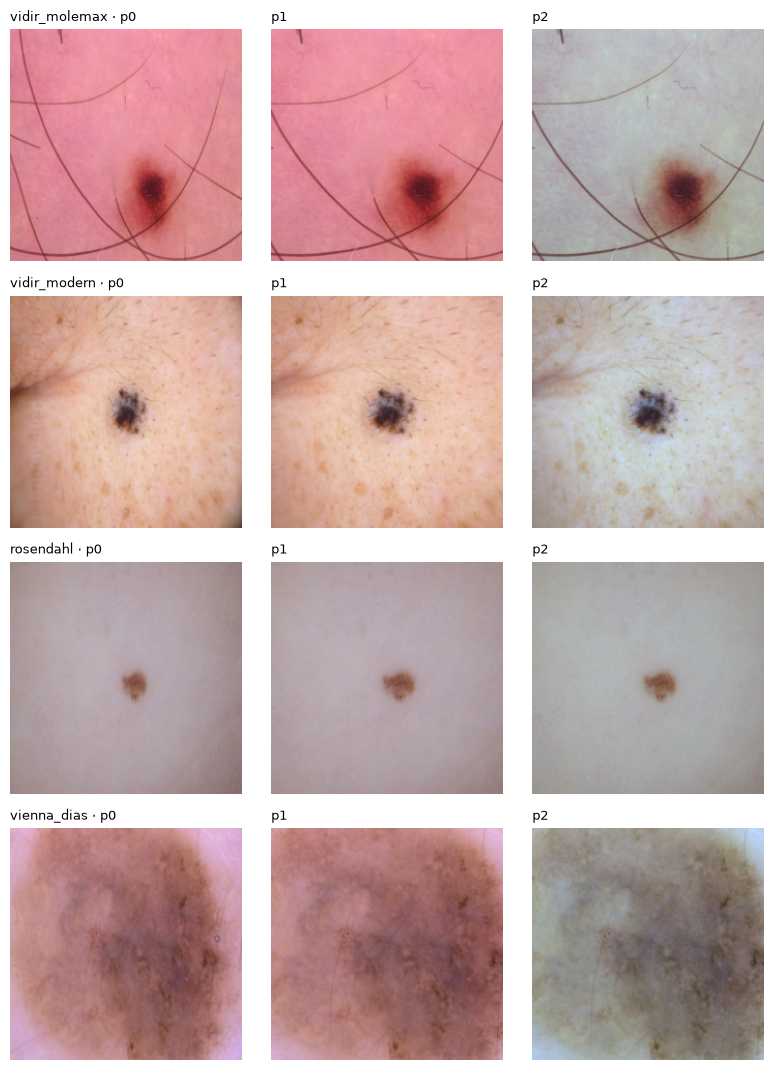

In [3]:
fig, ax = plt.subplots(len(NGUON), 3, figsize=(8, 2.7 * len(NGUON)))
for i, s in enumerate(NGUON):
    p = tv[(tv.nguon == s) & (tv.lop == "NV")].sample(1, random_state=3).duong_dan.iloc[0]
    for j, k in enumerate(("p0", "p1", "p2")):
        ax[i, j].imshow(doc_anh(p, 224, k)); ax[i, j].axis("off")
        ax[i, j].set_title(f"{s} · {k}" if j == 0 else k, fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(RA / "tien_xu_ly_so_sanh.png", dpi=110); plt.show()

## 3. Tầng rẻ: sau mỗi kiểu, còn đoán được nguồn không?

Đúng phép thử của notebook 03, chạy lại trên từng bộ đệm:

- **B**: 6 con số màu vùng giữa (trung bình và độ tản R, G, B), mọi lớp; đoán 4 nguồn, bừa được 0,25.
- **C**: như B nhưng chỉ ảnh NV. Ở P0 con số này phải ra lại đúng 0,80 của notebook 03 (vì cùng phép
  thử, cùng dữ liệu); không ra thì có gì đó sai.
- **C-sắc**: chỉ ảnh NV, chỉ dùng **sắc màu**: tỉ lệ r = R/(R+G+B) và g = G/(R+G+B), bỏ hẳn độ sáng.
  **Đây là con số của H1.**
- **V**: như C nhưng **chỉ hai nguồn ở Vienna**; đoán molemax hay modern, bừa được 0,5. **Đây là con
  số của H2.**

Ví dụ cho dễ hình dung: hai ảnh chụp cùng một tờ giấy trắng, một dưới đèn vàng, một dưới đèn trắng
nhưng tối hơn. Shades of Gray làm hai tờ giấy cùng trắng (sắc màu giống nhau), nhưng tấm tối vẫn tối hơn.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

def mau_giua(X, lo=1000):
    out = []
    for i in range(0, len(X), lo):
        g = X[i:i + lo, 56:168, 56:168].astype(np.float32)
        tb = g.mean((1, 2))
        sac = tb[:, :2] / np.maximum(tb.sum(1, keepdims=True), 1e-6)       # r, g: sắc màu, không có độ sáng
        out.append(np.column_stack([tb, g.std((1, 2)), sac]))
    return np.concatenate(out)          # 8 cột: 6 cột màu như notebook 03 + 2 cột sắc màu

def thu(F, d):
    y = d.nguon.map({s: i for i, s in enumerate(NGUON)}).values      # cùng cách mã hoá như notebook 03
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    yh = cross_val_predict(m, F, y, cv=StratifiedGroupKFold(5, shuffle=True, random_state=0),
                           groups=d.lesion_id.values)
    return balanced_accuracy_score(y, yh)

m_nv = (tv.lop == "NV").values
m_vie = m_nv & tv.nguon.isin(["vidir_molemax", "vidir_modern"]).values
hang = []
for k in ("p0", "p1", "p2"):
    F = mau_giua(nap_dem(cs, 224, k)[vt])
    M, S = F[:, :6], F[:, 6:]
    hang.append(dict(kieu=k, B_moi_lop=thu(M, tv), C_chi_NV=thu(M[m_nv], tv[m_nv]),
                     C_sac_chi_NV=thu(S[m_nv], tv[m_nv]), V_Vienna_2_may=thu(M[m_vie], tv[m_vie])))
    print("xong", k, flush=True)
bang_do = pd.DataFrame(hang).set_index("kieu").round(3)
bang_do

xong p0
xong p1
xong p2


,B_moi_lop,C_chi_NV,C_sac_chi_NV,V_Vienna_2_may
kieu,,,,
p0,0.767,0.804,0.580,0.981
p1,0.762,0.799,0.568,0.980
p2,0.624,0.648,0.390,0.820


In [5]:
def mau_da(X, lo=1000):
    out = []
    for i in range(0, len(X), lo):
        x = X[i:i + lo]
        s = np.concatenate([x[:, 8:32, 56:168], x[:, 192:216, 56:168]], 1).astype(np.float32)
        out.append(np.column_stack([s.mean((1, 2)), s.std((1, 2))]))
    return np.concatenate(out)

hang = []
for k in ("p0", "p2"):
    F = mau_da(nap_dem(cs, 224, k)[vt])
    hang.append(dict(kieu=k, C_da_chi_NV=thu(F[m_nv], tv[m_nv]), V_da_Vienna_2_may=thu(F[m_vie], tv[m_vie])))
pd.DataFrame(hang).set_index("kieu").round(3)

,C_da_chi_NV,V_da_Vienna_2_may
kieu,,
p0,0.776,0.987
p2,0.562,0.761


## 4. Tầng đắt: huấn luyện tập trung với P1 và P2

Kết quả P0 đã có sẵn (3 seed, pipeline thô). Còn thiếu 6 lượt: P1 và P2, mỗi kiểu 3 seed. Mỗi lượt
khoảng 7 phút, tổng cộng chừng **45 phút** GPU. Dán đoạn sau vào terminal (cửa sổ WSL). Nó chạy nền và
ghi nhật ký, nên cậu cứ làm việc khác trong lúc chờ:

```bash
cd ~/ham_fl && source .venv/bin/activate && mkdir -p ketqua/nhat_ky
nohup bash -c 'for s in 0 1 2; do for p in p1 p2; do python huan_luyen_tap_trung.py --backbone efficientnet_b0 --kt 224 --epoch 15 --seed $s --tien-xu-ly $p; done; done' > ketqua/nhat_ky/tien_xu_ly.txt 2>&1 &
```

Xem tiến độ: `tail -n 5 ketqua/nhat_ky/tien_xu_ly.txt`. Chạy xong thì quay lại notebook này và chạy ô
dưới.

In [6]:
hang = []
for f in glob.glob(str(RA / "tap_trung" / "efficientnet_b0_kt224_nghich*_s*.json")):
    j = json.load(open(f))
    hang.append(dict(kieu=j["cau_hinh"].get("tien_xu_ly", "p0"), seed=j["cau_hinh"]["seed"],
                     val=j["ket_qua"]["val"]["bacc"], test=j["ket_qua"]["test"]["bacc"],
                     test_auc=j["ket_qua"]["test"]["auc_macro"]))
kq = pd.DataFrame(hang)
bang_hl = kq.groupby("kieu").agg(n=("seed", "size"), val_tb=("val", "mean"), val_sd=("val", "std"),
                                test_tb=("test", "mean"), test_sd=("test", "std"), test_auc=("test_auc", "mean")).round(3)
bang_hl

,n,val_tb,val_sd,test_tb,test_sd,test_auc
kieu,,,,,,
p0,3,0.775,0.012,0.691,0.007,0.945
p1,3,0.778,0.005,0.714,0.029,0.953
p2,3,0.781,0.009,0.687,0.013,0.949


## 5. Tóm tắt

Ô dưới in một khối tóm tắt. **Dán khối đó cho tớ** kèm một câu nhận xét về hình so sánh ba kiểu ở mục 2.

In [7]:
print("===== TÓM TẮT NOTEBOOK 04 =====")
print("Đoán nguồn (B, C, C-sắc: bừa 0.25 · V: bừa 0.50):")
print(bang_do.to_string())
print("\nTập trung EfficientNet-B0 (balanced accuracy):")
print(bang_hl.to_string() if len(bang_hl) else "chưa có lượt nào")

===== TÓM TẮT NOTEBOOK 04 =====
Đoán nguồn (B, C, C-sắc: bừa 0.25 · V: bừa 0.50):
      B_moi_lop  C_chi_NV  C_sac_chi_NV  V_Vienna_2_may
kieu                                                   
p0        0.767     0.804         0.580           0.981
p1        0.762     0.799         0.568           0.980
p2        0.624     0.648         0.390           0.820

Tập trung EfficientNet-B0 (balanced accuracy):
      n  val_tb  val_sd  test_tb  test_sd  test_auc
kieu                                               
p0    3   0.775   0.012    0.691    0.007     0.945
p1    3   0.778   0.005    0.714    0.029     0.953
p2    3   0.781   0.009    0.687    0.013     0.949


## Kết luận bước 5  ·  *(viết sau khi có số)*

| Giả thuyết | Kết quả | Quyết định |
|---|---|---|
| H1: P2 xoá chữ ký sắc màu (C-sắc < 0,5) | | P2 có đáng mang vào bước 8 không |
| H2: hai máy ở Vienna tách được nhau | | khác biệt do máy hay do bệnh nhân |
| H3: tập trung P0/P1/P2 | | chọn kiểu nào làm pipeline chuẩn cho bước 7–9 |